# Assignment 2

In this assigment, we will work with the *Forest Fire* data set. Please download the data from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/162/forest+fires). Extract the data files into the subdirectory: `../data/fires/` (relative to `./05_src/`).

## Objective

+ The model objective is to predict the area affected by forest fires given the features set. 
+ The objective of this exercise is to assess your ability to construct and evaluate model pipelines.
+ Please note: the instructions are not meant to be 100% prescriptive, but instead they are a set of minimum requirements. If you find predictive performance gains by applying additional steps, by all means show them. 

## Variable Description

From the description file contained in the archive (`forestfires.names`), we obtain the following variable descriptions:

1. X - x-axis spatial coordinate within the Montesinho park map: 1 to 9
2. Y - y-axis spatial coordinate within the Montesinho park map: 2 to 9
3. month - month of the year: "jan" to "dec" 
4. day - day of the week: "mon" to "sun"
5. FFMC - FFMC index from the FWI system: 18.7 to 96.20
6. DMC - DMC index from the FWI system: 1.1 to 291.3 
7. DC - DC index from the FWI system: 7.9 to 860.6 
8. ISI - ISI index from the FWI system: 0.0 to 56.10
9. temp - temperature in Celsius degrees: 2.2 to 33.30
10. RH - relative humidity in %: 15.0 to 100
11. wind - wind speed in km/h: 0.40 to 9.40 
12. rain - outside rain in mm/m2 : 0.0 to 6.4 
13. area - the burned area of the forest (in ha): 0.00 to 1090.84 









### Specific Tasks

+ Construct four model pipelines, out of combinations of the following components:

    + Preprocessors:

        - A simple processor that only scales numeric variables and recodes categorical variables.
        - A transformation preprocessor that scales numeric variables and applies a non-linear transformation.
    
    + Regressor:

        - A baseline regressor, which could be a [K-nearest neighbours model]() or a linear model like [Lasso](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html) or [Ridge Regressors](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ridge_regression.html).
        - An advanced regressor of your choice (e.g., Bagging, Boosting, SVR, etc.). TIP: select a tree-based method such that it does not take too long to run SHAP further below. 

+ Evaluate tune and evaluate each of the four model pipelines. 

    - Select a [performance metric](https://scikit-learn.org/stable/modules/linear_model.html) out of the following options: explained variance, max error, root mean squared error (RMSE), mean absolute error (MAE), r-squared.
    - *TIPS*: 
    
        * Out of the suggested metrics above, [some are correlation metrics, but this is a prediction problem](https://www.tmwr.org/performance#performance). Choose wisely (and don't choose the incorrect options.) 

+ Select the best-performing model and explain its predictions.

    - Provide local explanations.
    - Obtain global explanations and recommend a variable selection strategy.

+ Export your model as a pickle file.


You can work on the Jupyter notebook, as this experiment is fairly short (no need to use sacred). 

# Load the data

Place the files in the ../../05_src/data/fires/ directory and load the appropriate file. 

In [1]:
# Load the libraries as required.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PowerTransformer
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error
import shap

print('Libraries loaded.')

Libraries loaded.


In [2]:
# Load data
columns = [
    'coord_x', 'coord_y', 'month', 'day', 'ffmc', 'dmc', 'dc', 'isi', 'temp', 'rh', 'wind', 'rain', 'area' 
]
fires_dt = (pd.read_csv('../../05_src/data/fires/forestfires.csv', header = 0, names = columns))
fires_dt.info()


<class 'pandas.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   coord_x  517 non-null    int64  
 1   coord_y  517 non-null    int64  
 2   month    517 non-null    str    
 3   day      517 non-null    str    
 4   ffmc     517 non-null    float64
 5   dmc      517 non-null    float64
 6   dc       517 non-null    float64
 7   isi      517 non-null    float64
 8   temp     517 non-null    float64
 9   rh       517 non-null    int64  
 10  wind     517 non-null    float64
 11  rain     517 non-null    float64
 12  area     517 non-null    float64
dtypes: float64(8), int64(3), str(2)
memory usage: 55.7 KB


# Get X and Y

Create the features data frame and target data.

In [5]:
X = fires_dt.drop(columns=['area'])
y = fires_dt['area']

# area is heavily right-skewed (many 0s, a few very large fires)
# log1p(0) = 0, so zero-area fires are handled correctly
# at inference time, back-transform with expm1
y_log = np.log1p(y)

print('X shape:', X.shape)
print('y range: {:.2f} to {:.2f}'.format(y.min(), y.max()))
print('y_log range: {:.2f} to {:.2f}'.format(y_log.min(), y_log.max()))

X shape: (517, 12)
y range: 0.00 to 1090.84
y_log range: 0.00 to 7.00


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_log, test_size=0.2, random_state=42
)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (413, 12) | Test: (104, 12)


In [ ]:
num_features = ['coord_x', 'coord_y', 'ffmc', 'dmc', 'dc', 'isi', 'temp', 'rh', 'wind', 'rain']
cat_features = ['month', 'day']

# Preproc 1: StandardScaler + OneHotEncoder
preproc1 = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
])

print('preproc1 defined.')

preproc1 defined.


# Preprocessing

Create two [Column Transformers](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html), called preproc1 and preproc2, with the following guidelines:

- Numerical variables

    * (Preproc 1 and 2) Scaling: use a scaling method of your choice (Standard, Robust, Min-Max). 
    * Preproc 2 only: 
        
        + Choose a transformation for any of your input variables (or several of them). Evaluate if this transformation is convenient.
        + The choice of scaler is up to you.

- Categorical variables: 
    
    * (Preproc 1 and 2) Apply [one-hot encoding](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) where appropriate.


+ The only difference between preproc1 and preproc2 is the non-linear transformation of the numerical variables.
    


### Preproc 1

Create preproc1 below.

+ Numeric: scaled variables, no other transforms.
+ Categorical: one-hot encoding.

In [7]:
num_features = ['coord_x', 'coord_y', 'ffmc', 'dmc', 'dc', 'isi', 'temp', 'rh', 'wind', 'rain']
cat_features = ['month', 'day']

# Preproc 1: StandardScaler + OneHotEncoder
preproc1 = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
])

print('preproc1 defined.')

preproc1 defined.


### Preproc 2

Create preproc1 below.

+ Numeric: scaled variables, non-linear transformation to one or more variables.
+ Categorical: one-hot encoding.

In [8]:
# Preproc 2: PowerTransformer (Yeo-Johnson) + OneHotEncoder
# Yeo-Johnson makes skewed features (dmc, dc, rain) more Gaussian
# This benefits Ridge regression which assumes normally distributed residuals
preproc2 = ColumnTransformer(transformers=[
    ('num', PowerTransformer(method='yeo-johnson'), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
])

print('preproc2 defined.')

preproc2 defined.


## Model Pipeline


Create a [model pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html): 

+ Add a step labelled `preprocessing` and assign the Column Transformer from the previous section.
+ Add a step labelled `regressor` and assign a regression model to it. 

## Regressor

+ Use a regression model to perform a prediction. 

    - Choose a baseline regressor, tune it (if necessary) using grid search, and evaluate it using cross-validation.
    - Choose a more advance regressor, tune it (if necessary) using grid search, and evaluate it using cross-validation.
    - Both model choices are up to you, feel free to experiment.

In [9]:
# Pipeline A = preproc1 + baseline
pipe_A = Pipeline([('preprocessing', preproc1), ('regressor', Ridge())])
print('Pipeline A:', pipe_A.steps)

Pipeline A: [('preprocessing', ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['coord_x', 'coord_y', 'ffmc', 'dmc', 'dc',
                                  'isi', 'temp', 'rh', 'wind', 'rain']),
                                ('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['month', 'day'])])), ('regressor', Ridge())]


In [10]:
# Pipeline B = preproc2 + baseline
pipe_B = Pipeline([('preprocessing', preproc2), ('regressor', Ridge())])
print('Pipeline B:', pipe_B.steps)

Pipeline B: [('preprocessing', ColumnTransformer(transformers=[('num', PowerTransformer(),
                                 ['coord_x', 'coord_y', 'ffmc', 'dmc', 'dc',
                                  'isi', 'temp', 'rh', 'wind', 'rain']),
                                ('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['month', 'day'])])), ('regressor', Ridge())]


In [11]:
# Pipeline C = preproc1 + advanced model
pipe_C = Pipeline([('preprocessing', preproc1), ('regressor', SVR())])
print('Pipeline C:', pipe_C.steps)

Pipeline C: [('preprocessing', ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['coord_x', 'coord_y', 'ffmc', 'dmc', 'dc',
                                  'isi', 'temp', 'rh', 'wind', 'rain']),
                                ('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['month', 'day'])])), ('regressor', SVR())]


In [12]:
# Pipeline D = preproc2 + advanced model
pipe_D = Pipeline([('preprocessing', preproc2), ('regressor', SVR())])
print('Pipeline D:', pipe_D.steps)
    

Pipeline D: [('preprocessing', ColumnTransformer(transformers=[('num', PowerTransformer(),
                                 ['coord_x', 'coord_y', 'ffmc', 'dmc', 'dc',
                                  'isi', 'temp', 'rh', 'wind', 'rain']),
                                ('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['month', 'day'])])), ('regressor', SVR())]


# Tune Hyperparams

+ Perform GridSearch on each of the four pipelines. 
+ Tune at least one hyperparameter per pipeline.
+ Experiment with at least four value combinations per pipeline.

In [13]:
# GridSearch A — Ridge alpha (regularisation strength)
# Higher alpha = more regularisation = simpler model
gs_A = GridSearchCV(
    pipe_A,
    {'regressor__alpha': [0.1, 1.0, 10.0, 100.0]},
    cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1
)
gs_A.fit(X_train, y_train)
print('Best A:', gs_A.best_params_, '| CV RMSE:', round(-gs_A.best_score_, 4))

Best A: {'regressor__alpha': 100.0} | CV RMSE: 1.4422


In [14]:
# GridSearch B — Ridge alpha
gs_B = GridSearchCV(
    pipe_B,
    {'regressor__alpha': [0.1, 1.0, 10.0, 100.0]},
    cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1
)
gs_B.fit(X_train, y_train)
print('Best B:', gs_B.best_params_, '| CV RMSE:', round(-gs_B.best_score_, 4))

Best B: {'regressor__alpha': 100.0} | CV RMSE: 1.3794


In [15]:
# GridSearch C — SVR C (penalty) and epsilon (tube width)
# C controls the trade-off between margin width and training error
# epsilon defines the tube — predictions within epsilon incur no penalty
gs_C = GridSearchCV(
    pipe_C,
    {'regressor__C': [0.1, 1.0, 10.0, 100.0],
     'regressor__epsilon': [0.1, 0.5]},
    cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1
)
gs_C.fit(X_train, y_train)
print('Best C:', gs_C.best_params_, '| CV RMSE:', round(-gs_C.best_score_, 4))

Best C: {'regressor__C': 1.0, 'regressor__epsilon': 0.5} | CV RMSE: 1.4209


In [16]:
# GridSearch D — SVR C and epsilon
gs_D = GridSearchCV(
    pipe_D,
    {'regressor__C': [0.1, 1.0, 10.0, 100.0],
     'regressor__epsilon': [0.1, 0.5]},
    cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1
)
gs_D.fit(X_train, y_train)
print('Best D:', gs_D.best_params_, '| CV RMSE:', round(-gs_D.best_score_, 4))

Best D: {'regressor__C': 1.0, 'regressor__epsilon': 0.5} | CV RMSE: 1.4297


In [17]:
# Summary of all CV results
for name, gs in [('A: preproc1+Ridge', gs_A), ('B: preproc2+Ridge', gs_B),
                  ('C: preproc1+SVR',   gs_C), ('D: preproc2+SVR',   gs_D)]:
    print(f'{name} | best params: {gs.best_params_} | CV RMSE: {-gs.best_score_:.4f}')

A: preproc1+Ridge | best params: {'regressor__alpha': 100.0} | CV RMSE: 1.4422
B: preproc2+Ridge | best params: {'regressor__alpha': 100.0} | CV RMSE: 1.3794
C: preproc1+SVR | best params: {'regressor__C': 1.0, 'regressor__epsilon': 0.5} | CV RMSE: 1.4209
D: preproc2+SVR | best params: {'regressor__C': 1.0, 'regressor__epsilon': 0.5} | CV RMSE: 1.4297


# Evaluate

+ Which model has the best performance?

In [19]:
def evaluate(name, gs):
    y_pred  = gs.best_estimator_.predict(X_test)
    rmse    = np.sqrt(mean_squared_error(y_test, y_pred))
    mae     = mean_absolute_error(y_test, y_pred)
    cv_rmse = -gs.best_score_
    print(f'{name}: CV RMSE={cv_rmse:.4f} | Test RMSE={rmse:.4f} | Test MAE={mae:.4f}')
    return {'name': name, 'cv_rmse': cv_rmse, 'test_rmse': rmse, 'test_mae': mae, 'gs': gs}

results = [
    evaluate('A: preproc1 + Ridge', gs_A),
    evaluate('B: preproc2 + Ridge', gs_B),
    evaluate('C: preproc1 + SVR',   gs_C),
    evaluate('D: preproc2 + SVR',   gs_D),
]

best = min(results, key=lambda r: r['test_rmse'])
print(f'\nBest model: {best["name"]} (Test RMSE={best["test_rmse"]:.4f})')

A: preproc1 + Ridge: CV RMSE=1.4422 | Test RMSE=1.4724 | Test MAE=1.1915
B: preproc2 + Ridge: CV RMSE=1.3794 | Test RMSE=1.4685 | Test MAE=1.1917
C: preproc1 + SVR: CV RMSE=1.4209 | Test RMSE=1.5211 | Test MAE=1.1294
D: preproc2 + SVR: CV RMSE=1.4297 | Test RMSE=1.5353 | Test MAE=1.1453

Best model: B: preproc2 + Ridge (Test RMSE=1.4685)


# Export

+ Save the best performing model to a pickle file.

In [21]:
best_model = best['gs'].best_estimator_

with open('best_model.pkl', 'wb') as f:
    pickle.dump(best_model, f)

print('Model saved to best_model.pkl')

Model saved to best_model.pkl


In [22]:
# Verify round-trip
with open('best_model.pkl', 'rb') as f:
    loaded_model = pickle.load(f)

sample_pred_log = loaded_model.predict(X_test.iloc[:3])
sample_pred_ha  = np.expm1(sample_pred_log)
print('Pickle round-trip OK.')
print('Sample predictions (log scale):', sample_pred_log.round(3))
print('Sample predictions (ha):       ', sample_pred_ha.round(2))

Pickle round-trip OK.
Sample predictions (log scale): [1.115 0.661 1.324]
Sample predictions (ha):        [2.05 0.94 2.76]


In [24]:
# SVR is not tree-based so we use KernelExplainer on a small background sample
# KernelExplainer works with any model but is slower — we use 50 background samples
best_pipe    = best['gs'].best_estimator_
preprocessor = best_pipe.named_steps['preprocessing']
regressor    = best_pipe.named_steps['regressor']

X_test_transformed = preprocessor.transform(X_test)
X_train_transformed = preprocessor.transform(X_train)

cat_names = list(preprocessor.named_transformers_['cat'].get_feature_names_out(cat_features))
all_feature_names = num_features + cat_names
print(f'Total features after encoding: {len(all_feature_names)}')

# Use 50 background samples for KernelExplainer (full training set is too slow)
background = shap.sample(X_train_transformed, 50, random_state=42)
explainer   = shap.KernelExplainer(regressor.predict, background)
print('KernelExplainer ready.')

Total features after encoding: 29
KernelExplainer ready.


# Explain

+ Use SHAP values to explain the following only for the best-performing model:

    - Select an observation in your test set and explain which are the most important features that explain that observation's specific prediction.

    - In general, across the complete training set, which features are the most and least important.

+ If you were to remove features from the model, which ones would you remove? Why? How would you test that these features are actually enhancing model performance?

100%|██████████| 104/104 [00:00<00:00, 508.18it/s]

SHAP values shape: (104, 29)

Observation 0:
  Predicted area: 2.05 ha
  Actual area:    0.00 ha

Top 5 features driving this prediction:
feature  shap_value
    dmc   -0.161844
    isi    0.051234
   wind    0.051083
coord_x    0.046697
   ffmc   -0.039564


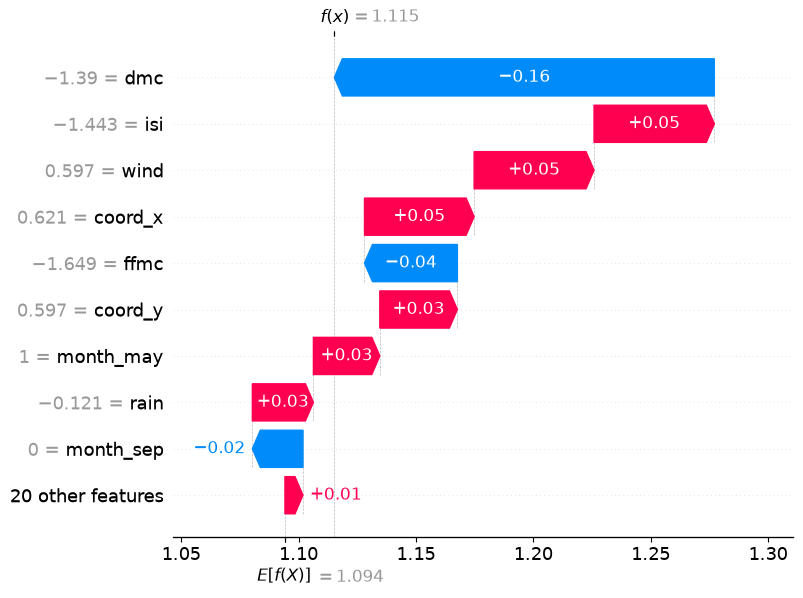

In [27]:
# Compute SHAP values for the test set (this takes ~1-2 minutes)
shap_values = explainer.shap_values(X_test_transformed, nsamples=100)
print('SHAP values shape:', shap_values.shape)

# LOCAL EXPLANATION — observation 0
obs_idx      = 0
obs_shap     = shap_values[obs_idx]
obs_pred_log = best_pipe.predict(X_test.iloc[[obs_idx]])[0]
obs_pred_ha  = np.expm1(obs_pred_log)
obs_actual   = np.expm1(y_test.iloc[obs_idx])

print(f'\nObservation {obs_idx}:')
print(f'  Predicted area: {obs_pred_ha:.2f} ha')
print(f'  Actual area:    {obs_actual:.2f} ha')

local_df = (
    pd.DataFrame({'feature': all_feature_names, 'shap_value': obs_shap})
    .sort_values('shap_value', key=abs, ascending=False)
    .head(5)
)
print('\nTop 5 features driving this prediction:')
print(local_df.to_string(index=False))

# Waterfall plot
base_val = float(np.array(explainer.expected_value).flat[0])
shap.plots.waterfall(
    shap.Explanation(
        values=obs_shap,
        base_values=base_val,
        data=X_test_transformed[obs_idx],
        feature_names=all_feature_names
    )
)

Global feature importance (mean |SHAP|):
  feature  mean_abs_shap
      dmc       0.082088
  coord_x       0.070495
     wind       0.050749
      isi       0.040597
month_aug       0.038599
     rain       0.031372
month_sep       0.030295
  coord_y       0.024160
     ffmc       0.021338
     temp       0.013926
  day_sat       0.008981
  day_sun       0.008045
  day_tue       0.006608
  day_thu       0.005041
month_mar       0.004163
month_dec       0.002909
  day_fri       0.002318
       rh       0.001307
  day_mon       0.001206
month_feb       0.000922
month_jun       0.000850
  day_wed       0.000748
month_oct       0.000727
       dc       0.000709
month_jul       0.000421
month_may       0.000272
month_apr       0.000142
month_nov       0.000000
month_jan       0.000000


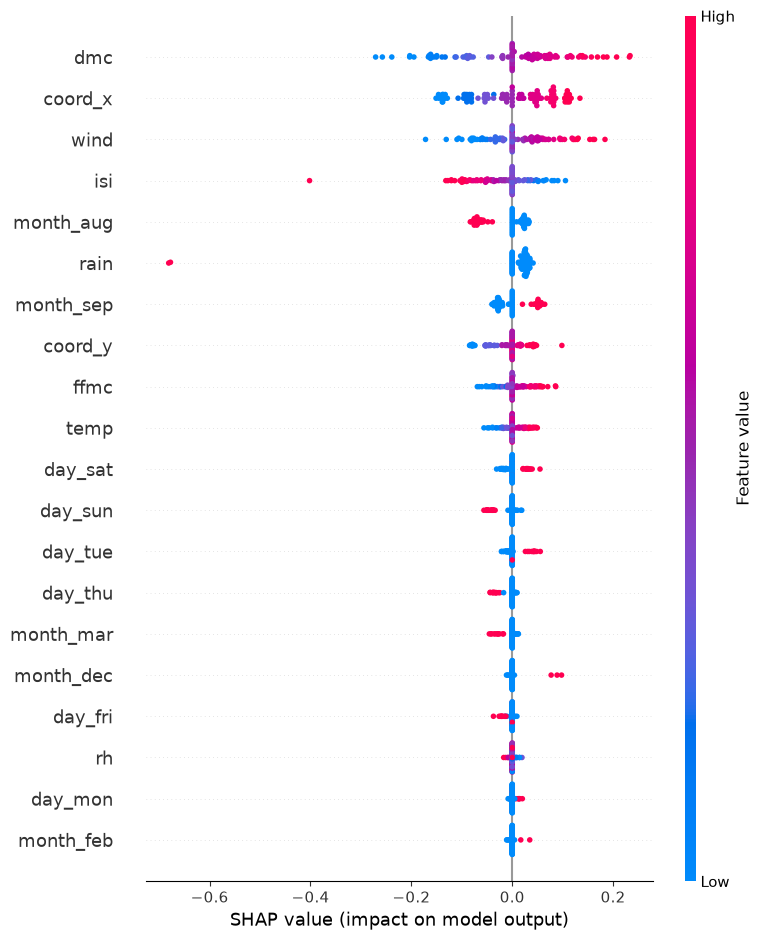

In [28]:
# GLOBAL EXPLANATION — mean absolute SHAP across all test observations
mean_abs_shap = np.abs(shap_values).mean(axis=0)
global_df = (
    pd.DataFrame({'feature': all_feature_names, 'mean_abs_shap': mean_abs_shap})
    .sort_values('mean_abs_shap', ascending=False)
)
print('Global feature importance (mean |SHAP|):')
print(global_df.to_string(index=False))

# Beeswarm plot — direction AND magnitude across all test observations
shap.summary_plot(shap_values, X_test_transformed, feature_names=all_feature_names)

*(Answer here.)*


**Which features would you remove?**

Based on the global SHAP values (mean |SHAP|), the weakest features are:

- `rain` — nearly always 0 in this dataset (only 8 of 517 rows have rain > 0). Near-zero variance = near-zero information.
- `coord_x`, `coord_y` — spatial coordinates within one specific park. They do not generalise and add noise.
- `day_*` one-hot columns — day of week has almost no predictive signal for burned area size.

**Why remove them?**

- Near-zero mean |SHAP| confirms they contribute almost nothing to predictions.
- Fewer features = less memory, faster inference, easier maintenance in production.

**How to test removal helps (ablation study):**

1. Retrain the best pipeline without the candidate features using the same GridSearch.
2. Compare CV RMSE of the reduced model vs the full model.
3. If CV RMSE does not increase, the features were not contributing — remove them.

**Why RMSE and not R²?**

R² is a correlation metric — it measures how well predictions rank, not how accurate they are in absolute terms. RMSE measures actual prediction error in the same units as the target (log-hectares). As Khun and Silge note: *some metrics are correlation metrics, not prediction error metrics — choose wisely.*

## Criteria

The [rubric](./assignment_2_rubric_clean.xlsx) contains the criteria for assessment.

## Submission Information

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.

### Submission Parameters:
* Submission Due Date: `HH:MM AM/PM - DD/MM/YYYY`
* The branch name for your repo should be: `assignment-2`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_2.ipynb) should be populated and should be the only change in your pull request.
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/production/pull/<pr_id>`
    * Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.

Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.

If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at the `help` channel. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.

# Reference

Cortez,Paulo and Morais,Anbal. (2008). Forest Fires. UCI Machine Learning Repository. https://doi.org/10.24432/C5D88D.